# 02 - Feature engineering
Point-in-time alignment and the seasonal-anomaly transform.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
R = ROOT / 'results'

In [2]:
zc = pd.read_csv(ROOT/'data/processed/features_zc.csv', index_col=0, parse_dates=True)
zc.filter(like='ia_railcars').dropna().tail(8)

,ia_railcars__wow,ia_railcars__ma4chg,ia_railcars__rel52,ia_railcars__yoy,ia_railcars__anom,ia_railcars__anomz
week,,,,,,
2026-09-11,-0.156111,0.061840,0.195274,-0.066148,0.513265,1.599343
2026-09-18,0.004981,0.094393,0.225271,-0.005231,0.589065,1.831810
2026-09-25,0.128446,0.174275,0.268682,0.096053,0.689506,2.138024
2026-10-02,-0.226244,-0.019392,0.203223,0.204380,0.643272,1.986486
2026-10-09,0.112595,0.018534,0.203689,0.231030,0.600133,1.846926
2026-10-16,-0.560738,-0.120788,0.090463,0.197552,0.444092,1.362816
2026-10-23,0.039935,-0.324837,-0.070449,0.110324,0.260666,0.798967
2026-10-30,-0.167054,-0.400046,-0.207184,-0.000153,0.120230,0.368567


**Leakage check**: for every decision week, the transport observation used must have been published before that Friday.

In [3]:
import feature_engineering as fe, data_cleaning as dc
raw = {r.columns[1]: r for r in dc.build_raw_weekly()}
for name in ['ia_railcars','insp_corn_mt','sales_corn_net_sales','barge_corn_tons']:
    t = fe.transform_series(raw[name]); t = t.dropna(subset=['available']).sort_values('available')
    t = t.assign(avail_key=t.available + pd.Timedelta(days=1))
    m = pd.merge_asof(pd.DataFrame({'week': zc.index}), t[['avail_key','available','obs_date']], left_on='week', right_on='avail_key')
    m = m.dropna(); print(f"{name:22s} violations (available >= decision Friday): {(m.available >= m.week).sum()}   median age of data used: {(m.week-m.obs_date).dt.days.median():.0f} days")

ia_railcars            violations (available >= decision Friday): 0   median age of data used: 7 days


insp_corn_mt           violations (available >= decision Friday): 0   median age of data used: 8 days


sales_corn_net_sales   violations (available >= decision Friday): 0   median age of data used: 8 days


barge_corn_tons        violations (available >= decision Friday): 0   median age of data used: 6 days


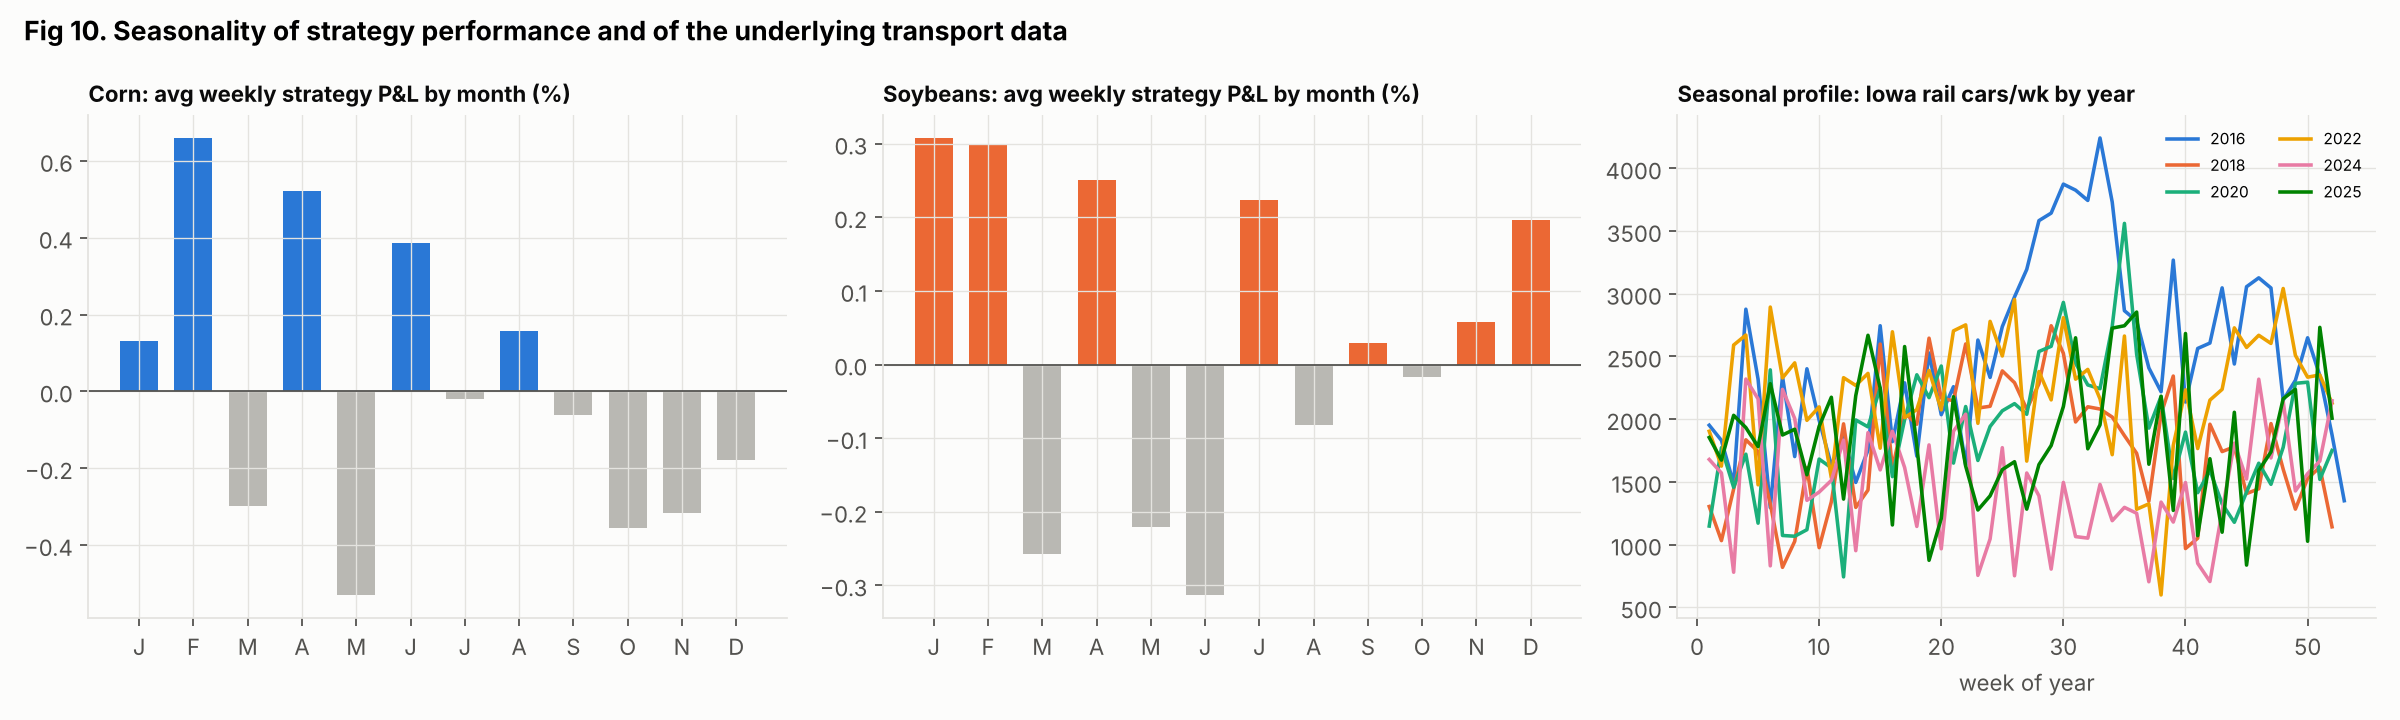

In [4]:
display(Image(R/'charts/10_seasonal_performance.png'))